In [11]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 2/13/2022
# version ='1.0'

# Demo: Experiments on using Block Elimination on Solving Minimum Length Piecewise-Linear Curve Subject to Equality Constraints

In the text book book-convex-2004, section 10.4, the problem of finding the minimum length piecewise-linear curve subject to equality constraints was discussed,
$$
\begin{array}{rcl}
\text{minimize} & & f(x)=(1+x_1^2)^{1/2}+\displaystyle{\sum_{i=1}^{n-1}(1+(x_{i-1}-x_{i})^2)^{1/2}} \\
\text{subject to} & & Ax=b \\
\end{array}
$$
where $x\in R^n$ and $A\in R^{m\times n}$. In solving the above minimization problem using Newton method, it generally requires solving the following KKT system by using a generic inversion (e.g. $nump.linalg.inv()$).
$$
\left[\begin{array}{cc}
H & A^T \\
A & 0 \\
\end{array} \right]\left[\begin{array}{c}
v \\
w \\
\end{array} \right] = -\left[\begin{array}{c}
g \\
h \\
\end{array} \right]
$$
However, in this problem, $f(x)$ is a sum of functions of pair of adjacent variables, so the hessian $H=\nabla^2 f(x)$ is tridiagonal, and the block elimination can be used to compute the Newton step given $H \succ 0$.

### Solving KKT system by block elimination
##### Given a KKT system with $H \succ 0$
\begin{itemize}
\item 1) Let $Q=H^{-1}A^T$ and $l=H^{-1}g$
\item 2) Let Schur complement $S=-AQ$
\item 3) Let $w=S^{-1}(Al-h)$
\item 4) Let $v=H^{-1}(-A^Tw-g)$
\end{itemize}


In the demo, the performance between the generic inversion and the block elimination in calculation of the Newton step is compared for a family of problems with $n=1000, m=5, 50, 100, 200, 300, 400, 500$. 

In [12]:
import numpy as np
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from scipy.linalg import eigh_tridiagonal
import time

$$ 
f(x)=(1+x_1^2)^{1/2}+\displaystyle{\sum_{i=1}^{n-1}(1+(x_{i-1}-x_{i})^2)^{1/2}}
$$

$$
    \begin{array}{rclcc}
            \nabla f(x) & =
                        & \left[
                           \begin{array}{c}
                            \alpha_1 - \alpha_2 \\
                            \cdots \\
                            \alpha_{n-1} - \alpha_n \\
                            \alpha_n \\
                            \end{array}
                          \right]
                        & \text{where}
                        & \alpha_i=(1+(x_i-x_{i-1})^2)^{-1/2}(x_i-x_{i-1}),x_0=0
    \end{array}
$$

$$
    \begin{array}{lcl}
        H_{i,i-1} & = & -(1+(x_{i}-x_{i-1})^2)^{1/2} \\
        H_{i,i} & = & (1+(x_{i}-x_{i-1})^2)^{1/2} + (1+(x_{i}-x_{i+1})^2)^{1/2} \\
        H_{i,i+1} & = & -(1+(x_{i}-x_{i+1})^2)^{1/2} \\
        \end{array}
    $$

In [13]:
def my_f(x):
    """
    $f(x)=(1+x_1^2)^{1/2}+\displaystyle{\sum_{i=1}^{n-1}(1+(x_{i-1}-x_{i})^2)^{1/2}}$
    :param x:
    :return:
    """
    n = len(x)
    x1 = x
    x2 = np.block([[0], [x[0: n - 1]]])
    q = x1 - x2
    return np.sum(np.sqrt(q ** 2 + 1)).item()


def my_gradient_f(x):
    """
    $$
    \begin{array}{rclcc}
            \nabla f(x) & =
                        & \left[
                           \begin{array}{c}
                            \alpha_1 - \alpha_2 \\
                            \cdots \\
                            \alpha_{n-1} - \alpha_n \\
                            \alpha_n \\
                            \end{array}
                          \right]
                        & \text{where}
                        & \alpha_i=(1+(x_i-x_{i-1})^2)^{-1/2}(x_i-x_{i-1}),x_0=0
    \end{array}
    $$
    :param x:
    :return:
    """
    n = len(x)
    g = np.zeros((n, 1))
    g[0] = ((1 + (x[0] ** 2)) ** -0.5) * x[0] + ((1 + (x[0] - x[1]) ** 2) ** -0.5) * (x[0] - x[1])
    g[n - 1] = ((1 + (x[n - 1] - x[n - 2]) ** 2) ** -0.5) * (x[n - 1] - x[n - 2])

    for i in range(1, n - 1):
        g[i] = ((1 + (x[i] - x[i - 1]) ** 2) ** -0.5) * (x[i] - x[i - 1]) + \
               ((1 + (x[i] - x[i + 1]) ** 2) ** -0.5) * (x[i] - x[i + 1])

    gradient = g
    return gradient


def my_hessian_f(x):
    """
    $\nabla^2 f(x)=[H_{i,j}]$

    $$
    \begin{array}{lcl}
        H_{i,i-1} & = & -(1+(x_{i}-x_{i-1})^2)^{1/2} \\
        H_{i,i} & = & (1+(x_{i}-x_{i-1})^2)^{1/2} + (1+(x_{i}-x_{i+1})^2)^{1/2} \\
        H_{i,i+1} & = & -(1+(x_{i}-x_{i+1})^2)^{1/2} \\
        \end{array}
    $$
    :param x:
    :return:
    """
    n = len(x)
    h = np.zeros((n, n))

    h[0, 0] = (1 + x[0] ** 2) ** -1.5 + (1 + (x[0] - x[1]) ** 2) ** -1.5
    h[0, 1] = -1 * (1 + (x[0] - x[1]) ** 2) ** -1.5

    for i in range(1, n - 1):
        h[i, i - 1] = -1 * (1 + (x[i - 1] - x[i]) ** 2) ** -1.5
        h[i, i] = (1 + (x[i] - x[i - 1]) ** 2) ** -1.5 + (1 + (x[i] - x[i + 1]) ** 2) ** -1.5
        h[i, i + 1] = -1 * (1 + (x[i + 1] - x[i]) ** 2) ** -1.5

    h[n - 1, n - 2] = -1 * (1 + (x[n - 1] - x[n - 2]) ** 2) ** -1.5
    h[n - 1, n - 1] = 1 * (1 + (x[n - 1] - x[n - 2]) ** 2) ** -1.5

    return h

Solve the problem via Newton’s method for equality constrained minimization, with feasible starting point
    use direct inversion to calculate matrix inversion

In [14]:
def my_newton_step_decrement_direct_inversion(x, A):
    """
    Solve the problem via Newton’s method for equality constrained minimization, with feasible starting point
    use direct inversion to calculate matrix inversion
    :param x:
    :param A:
    :return:
    """
    KKT_matrix = np.block([[my_hessian_f(x), A.T], [A, np.zeros((A.shape[0], A.shape[0]))]])
    minus_gradient = -1 * np.block([[my_gradient_f(x)], [np.zeros((A.shape[0], 1))]])
    conditional = np.linalg.cond(KKT_matrix)
    if conditional < 1 / sys.float_info.epsilon:
        newton_step = np.linalg.inv(KKT_matrix) @ minus_gradient
        x_nt = newton_step[0: len(x)]
        decrement = np.sqrt(x_nt.T @ my_hessian_f(x) @ x_nt).item()
        return x_nt, decrement, conditional
    else:
        raise RuntimeError("KKT matrix is not invertible.")

Solve the problem via Newton’s method for equality constrained minimization, with feasible starting point
    use block elimination to the tridiagonal hessian

In [15]:
def my_newton_step_decrement_block_elimination(x, A):
    """
    Solve the problem via Newton’s method for equality constrained minimization, with feasible starting point
    use block elimination to the tridiagonal hessian
    :param x:
    :param A:
    :return:
    """
    H = my_hessian_f(x)
    g = my_gradient_f(x)
    h = np.zeros((A.shape[0], 1))
    conditional = np.linalg.cond(H)
    if conditional > 1 / sys.float_info.epsilon:
        raise RuntimeError("H should be positive.")
    else:
        d = np.diag(H)
        e = np.diag(H, k=1)
        w, v = eigh_tridiagonal(d, e)
        H_inv = v @ np.diag(1 / w) @ v.T
        R = H_inv @ A.T
        r = H_inv @ g
        S = -A @ R
        w = np.linalg.inv(S) @ (A @ r - h)  # A@r-h=A@r as h=0s
        v = H_inv @ (-A.T @ w - g)
        x_nt = v

        decrement = np.sqrt(x_nt.T @ H @ x_nt).item()
        return x_nt, decrement, conditional

backtracking line search for Newton method

In [16]:
def backtracking_line_search_newton_method(f, df, x, delta_x, alpha, beta):
    """
    backtracking line search for Newton method
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :return:
    """
    t = 1
    while f(x + delta_x * t) > f(x) + alpha * t * ((df(x).T @ delta_x).item()):
        t = beta * t
    return t

Get the model parameter A, b for a feasible problem

Refer to the FlexibleLecture Note for more information

In [17]:
def get_A_b_feasible(n, m):
    """
    Get the model parameter A, b for a feasible problem
    Refer to the FlexibleLecture Note for more information
    :param n:
    :param m:
    :return:
    """
    A = np.random.rand(m, n)
    nu = np.zeros((m, 1))
    for mi in range(m):
        if mi % 2 == 0:
            nu[mi, 0] = np.random.sample()
        else:
            nu[mi, 0] = -1 * np.random.sample()

    beta = -1 * A.T @ nu
    sum_beta = np.sum(np.abs(beta))
    scale = 1 / sum_beta * 0.1
    nu_scaled = nu * scale
    beta_scaled = beta * scale

    alpha = np.zeros((n, 1))
    delta_i = np.zeros((n, 1))
    for i in range(n):
        alpha[i] = np.sum(beta_scaled[i :])
        sign = np.sign(alpha[i])
        delta_i[i] = sign * np.sqrt(alpha[i] ** 2 / (1 - alpha[i] ** 2))

    x_asterisk = np.zeros((n, 1))
    x_asterisk[0] = delta_i[0]
    for i in range(1, n):
        x_asterisk[i] = delta_i[i] + x_asterisk[i-1]

    b = A @ x_asterisk
    if not np.allclose(my_gradient_f(x_asterisk) + A.T @ nu_scaled, 0):
        raise RuntimeError('failure in generating A, b, nu')

    return A, b, x_asterisk, nu_scaled

Get another feasible point $x0$, such that $Ax_0=b$ from the optimal point $x^*$ which already satisfies $Ax^*=b$

In [18]:
def get_feasible_start_point(A, x_asterisk, b):
    """
    Get another feasible point $x0$, such that $Ax_0=b$ from the optimal point $x^*$ which already satisfies $Ax^*=b$
    :param A:
    :param x_asterisk:
    :param b:
    :return:
    """
    m, n = A.shape
    A_L = A[:, 0: m]
    A_R = A[:, m: n]
    x_r = np.random.uniform(-1, 1, (n-m, 1))
    x_l = -1 * np.linalg.inv(A_L) @ (A_R @ x_r)
    x0 = x_asterisk + np.block([[x_l], [x_r]])

    if not np.allclose(A @ x0 - b, 0):
        raise RuntimeError('Ax0 should be feasible')

    return x0

profiling in solving the minimum length piecewise curve problem for fix n and different m

In [19]:
def profiling_minimum_length_piecewise_curve_problem(n, ms, seed=2):
    """
    profiling in solving the minimum length piecewise curve problem for fix n and different m
    :param n:
    :param ms:
    :param seed:
    :return:
    """
    plt.figure(figsize=(12, 8))
    ax1 = plt.subplot(3, 1, 2)
    ax2 = plt.subplot(3, 1, 1)
    ax3 = plt.subplot(3, 1, 3)
    ax1.grid()
    ax2.grid()
    ax3.grid()

    method_names = ['direct inversion', 'block elimination']
    colors = ['black', 'blue']
    markers = [['o', 's', '+', '<', '>', '', '', '^'], ['o', 's', '+', '<', '>', '', '', '^']]
    elapse_time_log = np.zeros((len(method_names), len(ms)))
    for method_i, newton_step_decrement_f in enumerate([my_newton_step_decrement_direct_inversion,
                                                        my_newton_step_decrement_block_elimination]):
        for m_i, m in enumerate(ms):
            np.random.seed(seed)
            A, b, x_asterisk, _ = get_A_b_feasible(n, m)
            fmin = my_f(x_asterisk)
            x0 = get_feasible_start_point(A, x_asterisk, b)

            alpha = 0.5
            beta = 0.5
            epsilon = 1e-10
            max_iter = 40
            iteration = 0

            x = x0
            if not np.allclose(A @ x - b, 0):
                raise RuntimeError('it should be primal feasible.')

            fx = [my_f(x)]
            start_time = time.time()
            x_nt, decrement, condition = newton_step_decrement_f(x, A)
            stop_time = time.time()
            elapse_time = stop_time - start_time

            elapse_times = [elapse_time]
            kkt_conditions = [condition]

            while decrement / 2 > epsilon:
                #print('Info: m={}, method={}, iteration={}, decrement={}, fx={}'.format(m, method_names[method_i], iteration, decrement, my_f(x)))
                step = backtracking_line_search_newton_method(my_f, my_gradient_f, x, x_nt, alpha, beta)
                x_next = x + step * x_nt
                x = x_next

                fx.append(my_f(x))

                start_time = time.time()
                x_nt, decrement, condition = newton_step_decrement_f(x, A)
                stop_time = time.time()
                elapse_time = stop_time - start_time

                elapse_times.append(elapse_time)
                kkt_conditions.append(condition)

                iteration = iteration + 1
                if iteration > max_iter:
                    break

            #print('Info: m={}, method={}, iteration={} decrement={}, fx={}, |diff| = {}'.format(m, method_names[method_i], iteration, decrement, my_f(x), np.linalg.norm(x - x_asterisk)))

            elapse_time_log[method_i][m_i] = np.average(np.array(elapse_times))

            ax1.semilogy(kkt_conditions, color='{}'.format(colors[method_i]), fillstyle='none', marker='{}'.format(markers[method_i][m_i]),
                         label='n={},m={}, method={}'.format(n, m, method_names[method_i]))

            ax1.set_xlabel('iteration')
            ax1.set_ylabel(r'condition number, $\kappa$')
            ax1.set_xlim(0, max_iter)
            ax1.legend()
            ax1.xaxis.set_major_formatter(FormatStrFormatter('%d'))

            zeta = 1e-14
            ax2.semilogy(np.array(fx) - min(fmin, fx[-1]) + zeta, linestyle='dotted', color='{}'.format(colors[method_i]), fillstyle='none', marker='{}'.format(markers[method_i][m_i]),
                         label='n={},m={}, method={}'.format(n, m, method_names[method_i]))
            ax2.set_xlabel('iteration')
            ax2.set_ylabel(r'$f(x)-p^*$')
            ax2.set_xlim(0, max_iter)
            ax2.xaxis.set_major_formatter(FormatStrFormatter('%d'))

        ax3.plot(ms, elapse_time_log[method_i], color='{}'.format(colors[method_i]), fillstyle='none', marker='o', label=r'n={}, {}'.format(n,method_names[method_i]))
        ax3.set_xlabel('m')
        ax3.set_ylabel(r'average elapse time (second)')
        ax3.legend()

    plt.show()

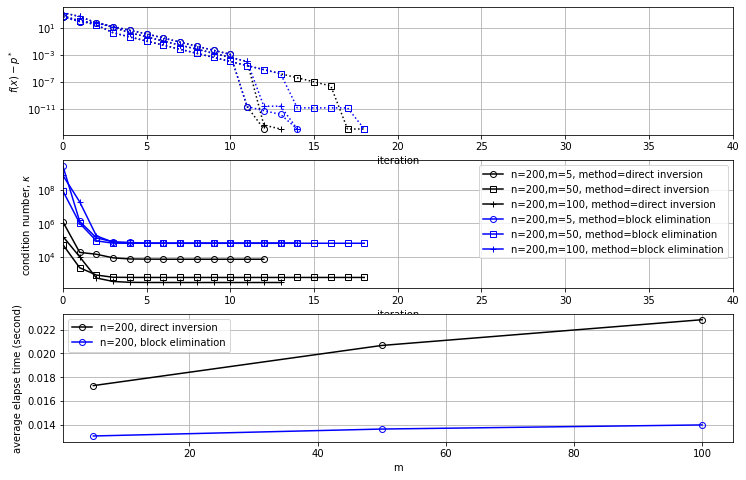

In [20]:
if __name__ == "__main__":
    profiling_minimum_length_piecewise_curve_problem(n=200, ms=[5, 50, 100], seed=3)